# Objekterkennung (Teil 2)

Potenzialanalyse für Dachflächen-Photovoltaik

Im letzten Arbeitsblatt wurden geeignete Dachflächen für den Einsatz von
Photovoltaikanlagen (PV-Anlagen) identifiziert.

In diesem interaktiven Arbeitsblatt sollen nun **bereits vorhandene
PV-Anlagen mithilfe von künstlicher Intelligenz auf Luftbildern erkannt
werden**. So können noch ungenutzte Dachflächen mit hohem Potenzial
ermittelt werden.

Ziel dieses Arbeitsblatts ist es, eine **Liste potenzieller Standorte**
zu erstellen. Diese Liste kann dazu beitragen, Eigentümer von geeigneten
Dächern zu motivieren, PV-Anlagen auf ihren Dächern zu installieren.

## 1 Orthophoto herunterladen

Ein Orthophoto ist ein verzerrungsfreies und maßstabsgetreues Luftbild,
das aus einem Flugzeug aufgenommen wurde.

Zunächst werden die Koordinaten (WGS 84) für unseren
Untersuchungsbereich bestimmt.

In [ ]:
from geopy import Nominatim

# Adresse festlegen
adresse = 'Upsprunger Str. 67, 33154 Salzkotten'

# Geocoder erstellen
geolocator = Nominatim(user_agent='my_user_agent')

# Breiten- und Längengrad bestimmen
location = geolocator.geocode(adresse)
coords = (location.latitude, location.longitude)
coords

Mit dem Befehl `download_orthophoto` kann ein Luftbild (Orthophoto) der
Umgebung heruntergeladen werden. Das Foto wird unter dem angegebenen
Pfad `path` gespeichert.

> **Hinweis**
>
> Das Herunterladen und Anzeigen des Fotos kann einige Sekunden dauern.
> Die Vorschau hat eine geringere Auflösung (2500 x 2500 px) als das
> Original (10000 x 10000 px).

In [ ]:
from util import download_orthophoto

# Pfad, unter dem das Orthophoto gespeichert wird (Ordner `data`)
path = 'data/orthophoto.jp2'

# Lade Orthophoto herunter
download_orthophoto(coords, path)

Mit dem Befehl `preview_orthophoto` kann eine Vorschau des gespeicherten
Fotos angezeigt werden. Dazu wird der Pfad der Datei angegeben.

In [ ]:
from util import preview_orthophoto

# Zeige Vorschau des Orthophotos
preview_orthophoto(path)

#### Aufgabe 1

-   Ändere die Adresse zu jener aus dem letzten Arbeitsblatt.
-   Lade das dazugehörige Orthophoto herunter, indem du die
    entsprechenden Zellen erneut ausführst.

*(5 Minuten)*

## 2 Objekterkennung mit künstlicher Intelligenz

Für die Erkennung von PV-Anlagen wird ein Modell des maschinellen
Lernens eingesetzt.

**Das Modell wurde darauf trainiert, PV-Anlagen auf Orthofotos zu
identifizieren** und zu markieren (siehe
<a href="#fig-object-detection" class="quarto-xref">Abb. 1</a>). Dafür
wurden dem Modell eine Auswahl an Orthophotos präsentiert, auf denen
PV-Anlagen bereits manuell markiert wurden. Anhand dieser Beispiele
(Trainingsdaten) hat das Modell gelernt, wie eine PV-Anlage aussieht,
und kann diese nun automatisch erkennen.

<figure id="fig-object-detection">
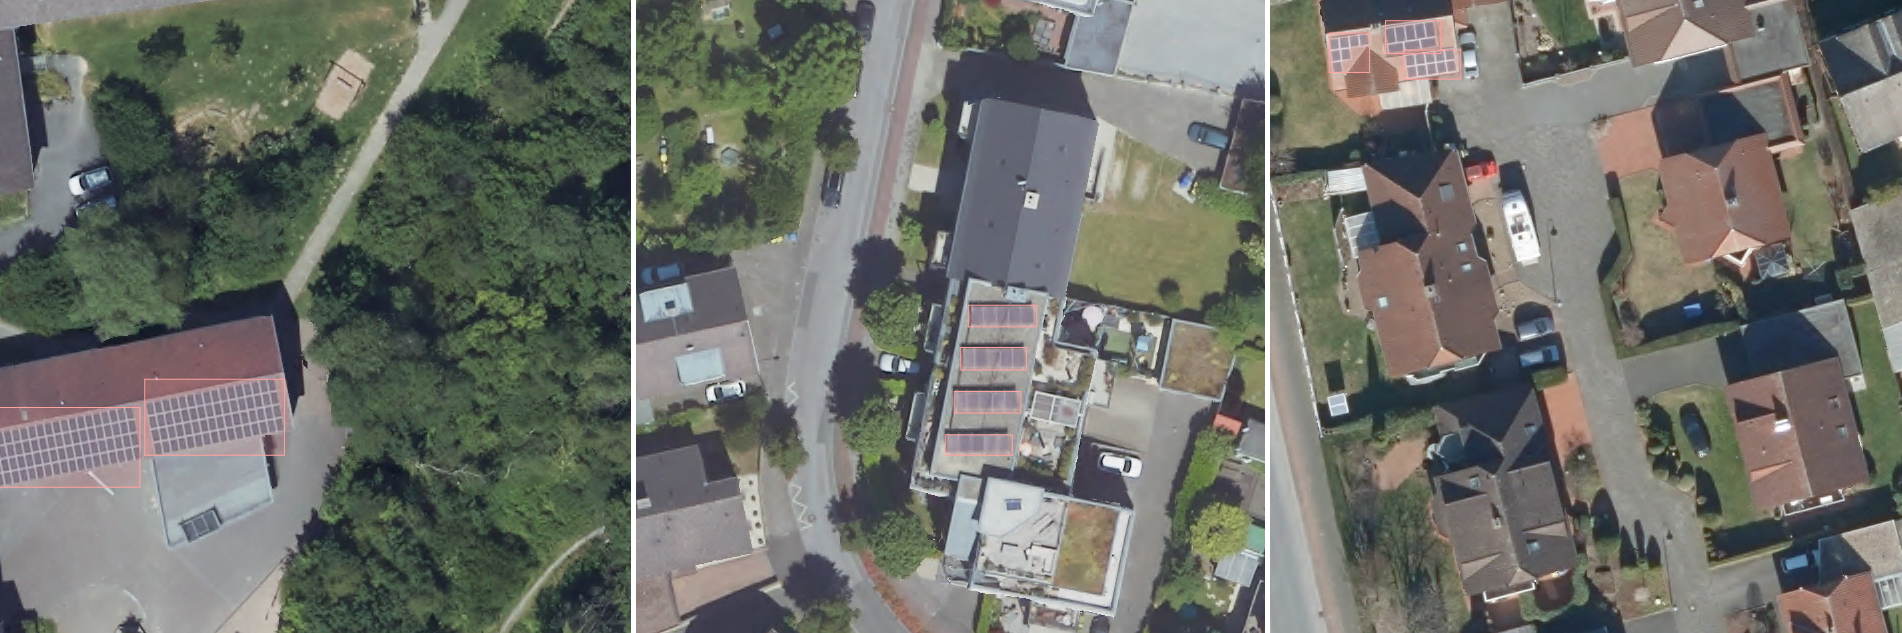
<figcaption>Abbildung 1: Trainingsdaten zur Erkennung von
PV-Anlagen</figcaption>
</figure>

Zunächst wird das Modell in den Arbeitsspeicher geladen.

In [ ]:
from util import ObjectDetection

# Modell laden
model = ObjectDetection()

Mit der Methode `predict` lässt sich nun eine Vorhersage des Modells für
das Orthophoto erzeugen. Dazu wird der Pfad des Bildes angegeben.

> **Hinweis**
>
> Im Bereich des maschinellen Lernens wird häufig der Begriff
> “Vorhersage” (Prediction) verwendet. Damit ist jedoch nicht
> zwangsläufig eine Aussage über die Zukunft gemeint. In diesem Fall ist
> damit das Ergebnis der Objekterkennung gemeint.

In [ ]:
# Vorhersage erstellen
result = model.predict(path)

#### Aufgabe 2

Schau dir das Ergebnis der Objekterkennung genauer an und suche nach
Fehlern:

-   Finde ein Beispiel, bei dem das Modell eine PV-Anlage übersehen hat
    (False Negative).
-   Finde ein Beispiel, bei dem das Modell fälschlicherweise eine
    PV-Anlage erkannt hat, obwohl dort keine vorhanden ist (False
    Positive).

**Welcher der beiden Fehlerarten ist deiner Meinung nach
schwerwiegender? Begründe deine Antwort!**

*(15 Minuten)*

In [ ]:
result.explore(height=800)

**Antwort**

*Klicke hier, um deine Antwort einzugeben!*

## 3 Evaluation des Modells

Um zu überprüfen, wie gut ein Modell zur Objekterkennung geeignet ist,
wird es evaluiert.  
Dabei wird gemessen, wie genau und zuverlässig das Modell die Objekte
erkennt. Zwei wichtige Maße (Metriken), die dabei oft verwendet werden,
sind **Precision (Genauigkeit) und Recall (Trefferquote)**.

### 3.1 Genauigkeit (Precision)

Die Genauigkeit (Precision) gibt an, **wie viele der vom Modell
erkannten Objekte tatsächlich richtig erkannt wurden**.

$$\text{Precision}=\frac{\text{Anzahl der richtig erkannten Objekte}}{\text{Anzahl aller erkannten Objekte}}$$

**Beispiel:** Angenommen, ein Objekterkennungsmodell identifiziert 50
Objekte auf Dachflächen als PV-Anlagen. Davon sind tatsächlich 45
PV-Anlagen (True Positives) und 5 Objekte sind keine PV-Anlagen, wurden
aber fälschlicherweise als solche erkannt (False Positives).

$$\text{Precision}=\frac{45}{50} = 0.9 = 90\%$$

Eine hohe Precision bedeutet, dass das Modell sehr genau darin ist,
PV-Anlagen zu identifizieren, und nur wenige falsche Positive
(Nicht-PV-Anlagen, die fälschlicherweise als PV-Anlagen erkannt wurden)
erzeugt.

### 3.2 Trefferquote (Recall)

Die Trefferquote (Recall) gibt, **wie viele der tatsächlich vorhandenen
Objekte vom Modell erkannt wurden**.

$$\text{Recall}=\frac{\text{Anzahl der richtig erkannten Objekte}}{\text{Anzahl aller tatsächlich vorhandenen Objekte}}$$

**Beispiel:** Angenommen, auf den analysierten Hausdächern befinden sich
insgesamt 60 PV-Anlagen. Das Modell erkennt davon 45 korrekt (True
Positives), übersieht jedoch 15 Anlagen (False Negatives), die
tatsächlich existieren. Der Recall wäre dann:

$$\text{Recall}=\frac{45}{60} = 0.75 = 75\%$$

Ein hoher Recall bedeutet, dass das Modell in der Lage ist, die meisten
vorhandenen PV-Anlagen zu erkennen, also nur wenige davon übersieht.

#### Aufgabe 3

Dem Modell wurden Orthophotos mit insgesamt 400 PV-Anlagen gezeigt.
Davon hat das Modell 309 korrekt erkannt. In 108 Fällen erkannte das
Modell fälschlicherweise eine PV-Anlage.

|                 | Vorhersage: PV-Anlage | Vorhersage: Hintergrund |
|-----------------|-----------------------|-------------------------|
| **PV-Anlage**.  | 309 (TP)              | 91 (FN)                 |
| **Hintergrund** | 108 (FP)              |                         |

**Berechne Precision und Recall für das Modell!**

*(10 Minuten)*

In [ ]:
# Hier Programmcode eingeben

**Antwort**

*Klicke hier, um deine Antwort einzugeben!*

> **Hinweis**
>
> In der Praxis ist es oft eine Herausforderung, ein Modell zu
> entwickeln, das sowohl eine hohe Precision als auch einen hohen Recall
> erreicht. Es kommt daher meist zu einen Kompromiss:
>
> -   Hohe Precision kann bedeuten, dass das Modell sehr selektiv ist
>     und nur dann eine PV-Anlage identifiziert, wenn es sich sehr
>     sicher ist. Dies führt zu wenigen False Positives, aber es könnte
>     viele tatsächliche PV-Anlagen übersehen (niedriger Recall).
> -   Hoher Recall kann bedeuten, dass das Modell sehr sensitiv ist und
>     versucht, möglichst alle PV-Anlagen zu erkennen. Dies führt zu
>     wenigen False Negatives, aber es könnte auch viele Objekte
>     fälschlicherweise als PV-Anlagen identifizieren (niedrige
>     Precision).

## 4 Solarkatasterdaten laden

Nachdem nun erkannt wurde, wo bereits PV-Anlagen vorhanden sind, können
diese Standorte von der bisher erstellten Liste entfernt werden.

Dazu wird zunächst das Zwischenergebnis aus dem letzten Arbeitsblatt
geladen.

In [ ]:
from geopandas import read_file

solarkataster = read_file('data/solarkataster.json').set_index('id')
solarkataster

## 5 Daten zusammenführen

Nun können die Ergebnisse zusammenführt werden: Der folgende Code
entfernt alle Dachflächen von Gebäuden aus dem Solarkataster, auf denen
sich bereits eine PV-Anlage befindet.

> **Hinweis**
>
> Der folgenden Programmcode enthält einige Funktionen, die nicht
> ausführlich erklärt werden. Es ist nicht notwendig, dass du jeden
> Befehl nachvollziehen kannst.

In [ ]:
import geopandas as gpd

# Schnittmenge zwischen den Daten bilden
intersection = gpd.sjoin(solarkataster, result, how='inner', predicate='intersects')
# Gebaeude IDs aus der Schnittmenge bestimmen
geb_ids = intersection['geb_id'].unique()
# Solarkatasterdaten anhand der Gebauede IDs filtern
solarkataster = solarkataster[~solarkataster['geb_id'].isin(geb_ids)]
# Daten visualiseren
solarkataster.explore(width=800, height=600)

## 6 Daten sortieren

Zuletzt sortieren werden die Daten absteigend nach der
Bestrahlungsenergie pro Quadratmeter sortiert.

In [ ]:
# Dachflächen nach Bestrahlungsenergie pro Quadratmeter sortieren
sorted_df = solarkataster.sort_values('total_energy_per_square_metre', ascending=False)
sorted_df

Mit Hilfe der Methode `iloc[]` können die Einträge anhand der
Reihenfolge der Daten ausgewählt werden.

In [ ]:
# Die ersten 100 Dachflächen auswählen
sorted_df.iloc[:100]

#### Aufgabe 4

-   Erstelle eine Liste mit 10 Dachflächen, auf denen deiner Meinung
    nach der Einsatz von PV-Anlagen sinnvoll wäre.

*(10 Minuten)*

In [ ]:
# Hier Code einfügen

## 7 Zusammenfassung – Objekterkennung

In diesem Notebook hast du gelernt, wie du:

-   mit einem KI-gestützten Objekterkennungsmodell bereits installierte
    PV-Anlagen auf Luftbildern (Orthofotos) identifizierst,
-   Luftbilddaten (Orthofotos) als Input für eine Objekterkennung
    aufbereitest,
-   die Vorhersagen des Modells mit geeigneten Metriken evaluierst,
    z. B. Präzision, Recall oder F1-Score,
-   die Bedeutung der Erkennung vorhandener Anlagen für die Planung
    neuer Installationen verstehst,
-   eine Liste potenzieller neuer Standorte erstellst, die für
    Eigentümer interessant sein könnten,
-   den Gesamtzusammenhang zwischen technischer Analyse, KI und
    Klimaschutz erkennst.